In [1]:
import torch
import transformers
import peft
import datasets

/home/hasan-hafizov/miniconda3/envs/audio/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### 1-kod katagi izohi: Kutubxonalarni yuklash

`import` kutubxonalarni Python muhitiga ulaydi.

- `torch` — tensorlar, GPU hisoblashlari va neyron tarmoqlar bilan ishlash uchun.
- `transformers` — tayyor til modeli va tokenizatorni yuklash, javob yaratish uchun.
- `peft` — LoRA kabi usullar bilan model parametrlarining kichik qismini o‘qitish uchun; bu katakda faqat import qilinadi.
- `datasets` — ma’lumotlar to‘plamlarini yuklash va qayta ishlash uchun.


### 2-kod katagi izohi: Bo‘sh katak

Bu katakda bajariladigan kod yo‘q. Uni ishga tushirish hisoblash bajarmaydi va o‘zgaruvchi yaratmaydi.


In [2]:
print("Pytorch version: ",torch.__version__)
print("Cuda: ",torch.cuda.is_available())
print("Cuda version: ",torch.version.cuda)

Pytorch version:  2.14.0+cu130
Cuda:  True
Cuda version:  13.0


### 3-kod katagi izohi: PyTorch va CUDA muhitini tekshirish

`torch.__version__` o‘rnatilgan PyTorch versiyasini chiqaradi. `torch.cuda.is_available()` CUDA orqali GPU ishlatish mumkinligini `True` yoki `False` sifatida bildiradi.

`torch.version.cuda` PyTorch yig‘ilgan CUDA versiyasini ko‘rsatadi; bu kompyuterdagi barcha CUDA vositalarining versiyasi degani emas. CPU uchun yig‘ilgan PyTorchda qiymat `None` bo‘lishi mumkin.


In [3]:
if torch.cuda.is_available():
    print("GPU: ",torch.cuda.get_device_name(0))

    vram=torch.cuda.get_device_properties(0).total_memory
    print("Vram: ",vram/1024**3,"GB")

GPU:  NVIDIA GeForce RTX 3060 Laptop GPU
Vram:  5.67022705078125 GB


### 4-kod katagi izohi: GPU nomi va umumiy xotirasi

Kod faqat CUDA mavjud bo‘lsa ishlaydi. `get_device_name(0)` birinchi GPU nomini, `get_device_properties(0).total_memory` esa uning umumiy video xotirasini baytlarda oladi.

`1024**3` ga bo‘lish baytni GiB ga aylantiradi, garchi ekranga `GB` yozuvi chiqarilsa ham. Bu bo‘sh xotira emas, GPUning jami xotirasidir.


In [4]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

dtype=(
    torch.bfloat16
    if torch.cuda.is_bf16_supported() else torch.float16
)

print(device)
print(dtype)


cuda
torch.bfloat16


### 5-kod katagi izohi: Hisoblash qurilmasi va sonlar turi

`device` CUDA mavjud bo‘lsa `cuda`, aks holda `cpu` bo‘ladi. Keyinchalik model va kirish tensorlari shu qurilmaga ko‘chiriladi.

`dtype` BF16 qo‘llab-quvvatlansa `torch.bfloat16`, aks holda `torch.float16` qilib tanlanadi. Ikkalasi ham 16 bitli suzuvchi nuqta formatlari; ularning son diapazoni va aniqligi farq qiladi.

Bu yerda tur faqat o‘zgaruvchiga yoziladi. Quyidagi model yuklash katagi `dtype` o‘zgaruvchisini ishlatmaydi, balki BF16 ni bevosita belgilaydi.


Upload the Model 

In [5]:
from transformers import AutoTokenizer,AutoModelForCausalLM

model_name="Qwen/Qwen2.5-0.5B-Instruct"

tokenizer=AutoTokenizer.from_pretrained(model_name)
model=AutoModelForCausalLM.from_pretrained(model_name,torch_dtype=torch.bfloat16)

model=model.to(device)

`torch_dtype` is deprecated! Use `dtype` instead!


### 6-kod katagi izohi: Model va tokenizatorni yuklash

`model_name` Hugging Face dagi `Qwen/Qwen2.5-0.5B-Instruct` modelini tanlaydi. `Instruct` suhbat va ko‘rsatmalarga javob berishga moslashtirilgan variantni bildiradi.

- `AutoTokenizer.from_pretrained(...)` matnni token ID lariga va aksincha aylantiruvchi tokenizatorni yuklaydi.
- `AutoModelForCausalLM.from_pretrained(...)` oldingi tokenlar asosida keyingi tokenni bashorat qiladigan til modelini yuklaydi; vaznlar uchun BF16 so‘ralgan.
- `model.to(device)` modelni tanlangan GPU yoki CPU ga ko‘chiradi.

Fayllar keshda bo‘lmasa, yuklash internet talab qiladi. BF16 bu katakda qat’iy berilgani sababli oldingi katakdagi FP16 tanlovi bu yerga ta’sir qilmaydi.


Checking parameters

In [6]:
total_parameters=0
trainable_parameters=0

for name,param in model.named_parameters():

    total_parameters+=param.numel()

    if param.requires_grad:

        trainable_parameters+=param.numel()

print("Total parameters: ",total_parameters)
print("Trainable parameters: ",trainable_parameters)

Total parameters:  494032768
Trainable parameters:  494032768


### 7-kod katagi izohi: Model parametrlarini sanash

`model.named_parameters()` parametrlarning nomi va tensorini bittadan beradi. `param.numel()` tensor ichidagi sonlar miqdorini qaytaradi.

`total_parameters` barcha parametr elementlarini, `trainable_parameters` esa `requires_grad=True` bo‘lganlarini jamlaydi. `requires_grad` gradient hisoblashga ruxsatni bildiradi; bu kodning o‘zi modelni o‘qitmaydi. `name` ushbu hisoblashda ishlatilmaydi.


Checking How much get Memory

In [7]:
print("Allocated:", torch.cuda.memory_allocated()/1024**3,"GiB")
print("Reserved: ", torch.cuda.memory_reserved()/1024**3,"GiB")

Allocated: 0.9278969764709473 GiB
Reserved:  0.96875 GiB


### 8-kod katagi izohi: GPU xotirasidan foydalanish

`memory_allocated()` PyTorch tensorlari hozir egallab turgan GPU xotirasini ko‘rsatadi. `memory_reserved()` PyTorch xotira boshqaruvchisi ajratib qo‘ygan, jumladan qayta foydalanish uchun saqlayotgan xotirani ko‘rsatadi.

Qiymatlar `1024**3` ga bo‘linib GiB da chiqariladi. Bular barcha dasturlarning jami GPU sarfini emas, PyTorch boshqarayotgan xotirani ifodalaydi.


Model architeckture

In [8]:
#model=model.to(device)
config=model.config

print("Architekture: ",config.architectures)
print("Hidden Size: ",config.hidden_size)
print("Layers: ",config.num_hidden_layers)
print("Attention heads: ",config.num_attention_heads)
print("KV heads: ",config.num_key_value_heads)
print("Intermediate size: ",config.intermediate_size)
print("Vocabulary Size: ",config.vocab_size)
print("Context length: ",config.max_position_embeddings)

Architekture:  ['Qwen2ForCausalLM']
Hidden Size:  896
Layers:  24
Attention heads:  14
KV heads:  2
Intermediate size:  4864
Vocabulary Size:  151936
Context length:  32768


### 9-kod katagi izohi: Model arxitekturasi sozlamalari

`model.config` model tuzilishi haqidagi sozlamalarni saqlaydi.

- `architectures` — model sinfi nomlari; `hidden_size` — har bir tokenning ichki vektor o‘lchami.
- `num_hidden_layers` — transformer bloklari soni.
- `num_attention_heads` — attention so‘rov boshlari soni; `num_key_value_heads` — key/value boshlari soni. Ular kamroq bo‘lsa, bir nechta so‘rov boshi key/value boshlarini bo‘lishadi.
- `intermediate_size` — blokdagi MLP oraliq qatlam o‘lchami.
- `vocab_size` — token lug‘ati o‘lchami; `max_position_embeddings` — konfiguratsiyadagi pozitsiyalar chegarasi.

`#model=model.to(device)` izohga olingan, shuning uchun bajarilmaydi. Konfiguratsiyadagi kontekst chegarasi amalda xotiraga sig‘adigan uzunlikni kafolatlamaydi.


In [9]:
print(model.model.layers[0])

Qwen2DecoderLayer(
  (self_attn): Qwen2Attention(
    (q_proj): Linear(in_features=896, out_features=896, bias=True)
    (k_proj): Linear(in_features=896, out_features=128, bias=True)
    (v_proj): Linear(in_features=896, out_features=128, bias=True)
    (o_proj): Linear(in_features=896, out_features=896, bias=False)
  )
  (mlp): Qwen2MLP(
    (gate_proj): Linear(in_features=896, out_features=4864, bias=False)
    (up_proj): Linear(in_features=896, out_features=4864, bias=False)
    (down_proj): Linear(in_features=4864, out_features=896, bias=False)
    (act_fn): SiLUActivation()
  )
  (input_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
  (post_attention_layernorm): Qwen2RMSNorm((896,), eps=1e-06)
)


### 10-kod katagi izohi: Birinchi transformer blokini ko‘rish

`model.model.layers[0]` transformer bloklari ro‘yxatidan birinchisini oladi: Python indekslari noldan boshlanadi.

`print` blokdagi attention, MLP va normalizatsiya modullari tuzilishini ko‘rsatadi. Bu model orqali matn o‘tkazmaydi va vaznlarni o‘zgartirmaydi.


In [10]:
for name, param in model.model.layers[0].named_parameters():
    print(
        name,
        "| Shape:", tuple(param.shape),
        "| Parameters:", param.numel()
    )

self_attn.q_proj.weight | Shape: (896, 896) | Parameters: 802816
self_attn.q_proj.bias | Shape: (896,) | Parameters: 896
self_attn.k_proj.weight | Shape: (128, 896) | Parameters: 114688
self_attn.k_proj.bias | Shape: (128,) | Parameters: 128
self_attn.v_proj.weight | Shape: (128, 896) | Parameters: 114688
self_attn.v_proj.bias | Shape: (128,) | Parameters: 128
self_attn.o_proj.weight | Shape: (896, 896) | Parameters: 802816
mlp.gate_proj.weight | Shape: (4864, 896) | Parameters: 4358144
mlp.up_proj.weight | Shape: (4864, 896) | Parameters: 4358144
mlp.down_proj.weight | Shape: (896, 4864) | Parameters: 4358144
input_layernorm.weight | Shape: (896,) | Parameters: 896
post_attention_layernorm.weight | Shape: (896,) | Parameters: 896


### 11-kod katagi izohi: Birinchi blok vaznlarining o‘lchamlari

Sikl birinchi blokdagi har bir parametr nomini, `tuple(param.shape)` orqali tensor shaklini va `param.numel()` orqali elementlar sonini chiqaradi.

Masalan, ikki o‘lchamli vazn matritsasida elementlar soni ikki o‘lchamning ko‘paytmasiga teng. Bu ma’lumot qaysi modul nechta parametr saqlashini tushunishga yordam beradi.


In [11]:
messages=[
    {
        "role":"user",
        "content":"O'zbekistonning poytaxti qaysi shahar?"
    }
]

prompt=tokenizer.apply_chat_template(
    messages,
    tokenize=False,
    add_generation_prompt=True
)

print(prompt)

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
O'zbekistonning poytaxti qaysi shahar?<|im_end|>
<|im_start|>assistant



### 12-kod katagi izohi: Savolni suhbat shabloniga o‘tkazish

`messages` suhbat xabarlarini saqlaydi: `role="user"` foydalanuvchini, `content` esa uning savolini bildiradi.

`apply_chat_template` xabarni model kutadigan suhbat ko‘rinishiga keltiradi. `tokenize=False` tokenlar emas, tayyor matn qaytaradi. `add_generation_prompt=True` model javobini boshlash uchun assistant belgisini qo‘shadi. `print(prompt)` shu matn va maxsus belgilarni ko‘rsatadi.


In [12]:
inputs = tokenizer(
    prompt,
    return_tensors="pt",
    add_special_tokens=False
).to(device)

print("Input IDs:", inputs["input_ids"])
print("Attention mask:",inputs["attention_mask"])
print("Shape:",inputs["input_ids"].shape)

Input IDs: tensor([[151644,   8948,    198,   2610,    525,   1207,  16948,     11,   3465,
            553,  54364,  14817,     13,   1446,    525,    264,  10950,  17847,
             13, 151645,    198, 151644,    872,    198,     46,      6,  75013,
          58819,   1229,    281,   2253,  17616,  10251,   2804,    942,     72,
            557,   1466,    277,     30, 151645,    198, 151644,  77091,    198]],
       device='cuda:0')
Attention mask: tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
         1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]],
       device='cuda:0')
Shape: torch.Size([1, 45])


### 13-kod katagi izohi: Promptni tensorlarga aylantirish

Tokenizator `prompt` matnini sonli token ID lariga aylantiradi. `return_tensors="pt"` natijani PyTorch tensorlari shaklida beradi; `.to(device)` ularni model turgan qurilmaga ko‘chiradi.

- `input_ids` — modelga beriladigan token raqamlari.
- `attention_mask` — haqiqiy tokenlarni odatda `1`, padding joylarini `0` bilan belgilaydi.
- `shape` odatda `[1, tokenlar_soni]`: bitta promptdan iborat batch.

`add_special_tokens=False` suhbat shablonida mavjud maxsus belgilar ustiga yana avtomatik belgilar qo‘shilishini oldini oladi.


In [13]:
tokens = tokenizer.convert_ids_to_tokens(
    inputs["input_ids"][0].tolist()
)

print(tokens)

['<|im_start|>', 'system', 'Ċ', 'You', 'Ġare', 'ĠQ', 'wen', ',', 'Ġcreated', 'Ġby', 'ĠAlibaba', 'ĠCloud', '.', 'ĠYou', 'Ġare', 'Ġa', 'Ġhelpful', 'Ġassistant', '.', '<|im_end|>', 'Ċ', '<|im_start|>', 'user', 'Ċ', 'O', "'", 'zbek', 'iston', 'ning', 'Ġp', 'oy', 'tax', 'ti', 'Ġq', 'ays', 'i', 'Ġsh', 'ah', 'ar', '?', '<|im_end|>', 'Ċ', '<|im_start|>', 'assistant', 'Ċ']


### 14-kod katagi izohi: Tokenlarning yozuvini ko‘rish

`inputs["input_ids"][0]` batchdagi birinchi promptni tanlaydi. `.tolist()` tensorni Python ro‘yxatiga o‘tkazadi.

`convert_ids_to_tokens` har bir ID ga mos token yozuvini qaytaradi. Token doim butun so‘z bo‘lavermaydi: so‘z bo‘lagi, tinish belgisi yoki maxsus belgi bo‘lishi mumkin. Bu butun javobni o‘qiladigan matnga aylantiruvchi `decode` bilan bir xil amal emas.


In [14]:
model.eval()

with torch.inference_mode():

    outputs = model.generate(
        **inputs,
        max_new_tokens=1024,
        do_sample=False
    )

input_length = inputs["input_ids"].shape[1]

new_tokens = outputs[0][input_length:]

answer = tokenizer.decode(
    new_tokens,
    skip_special_tokens=True
)

print(answer)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


O'zbekistonning poytaxti qaysi shahar 10000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000

### 15-kod katagi izohi: Modeldan javob yaratish

`model.eval()` modelni baholash rejimiga o‘tkazadi. `torch.inference_mode()` gradient hisoblashini o‘chirib, javob yaratishdagi ortiqcha hisoblash va xotira sarfini kamaytiradi.

`model.generate(**inputs, ...)` kirish lug‘atidagi tensorlarni argument sifatida uzatadi. `max_new_tokens=1024` yangi tokenlar uchun yuqori chegara; model tugash belgisini chiqarsa, oldinroq to‘xtaydi. `do_sample=False` bu chaqiruvda odatda har qadamda eng ehtimolli tokenni tanlashni bildiradi.

Natijada prompt tokenlari ham bo‘lgani uchun `input_length` orqali ular kesib tashlanadi. `decode(..., skip_special_tokens=True)` faqat yangi tokenlardan xizmat belgilarisiz javob matnini hosil qiladi.


In [15]:
import time
import torch

def inference(question, max_new_tokens=64):

    model.eval()

    messages = [
        {"role": "user", "content": question}
    ]

    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    ).to(device)

    input_length = inputs["input_ids"].shape[1]

    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()

    start_time = time.perf_counter()

    with torch.inference_mode():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False
        )

    torch.cuda.synchronize()

    elapsed_time = time.perf_counter() - start_time

    generated_tokens = outputs[0][input_length:]

    output_length = generated_tokens.numel()

    answer = tokenizer.decode(
        generated_tokens,
        skip_special_tokens=True
    )

    tokens_per_second = output_length / elapsed_time

    peak_vram = torch.cuda.max_memory_allocated() / 1024**3

    return {
        "question": question,
        "answer": answer,
        "input_tokens": input_length,
        "output_tokens": output_length,
        "latency": round(elapsed_time, 3),
        "tokens_per_second": round(tokens_per_second, 2),
        "peak_vram_gib": round(peak_vram, 3)
    }

### 16-kod katagi izohi: Javob va tezlikni o‘lchaydigan funksiya

`inference(question, max_new_tokens=64)` savolni suhbat shabloniga o‘tkazadi, tokenlashtiradi, modeldan javob oladi va natijani lug‘at ko‘rinishida qaytaradi. `max_new_tokens` berilmasa, chegara 64 bo‘ladi.

`torch.cuda.synchronize()` GPU ishlari tugashini kutadi: GPU amallari asinxron bo‘lgani uchun vaqtni aniqroq o‘lchashga yordam beradi. `reset_peak_memory_stats()` eng yuqori xotira sarfi hisoblagichini yangidan boshlaydi. `time.perf_counter()` yordamida generatsiya va uning tugashini kutish vaqti o‘lchanadi; prompt tayyorlash va tokenlashtirish bu vaqtga kirmaydi.

Qaytadigan qiymatlar: savol va javob, kirish/chiqish tokenlari soni, `latency` (soniya), `tokens_per_second` (chiqish tokenlari / vaqt), `peak_vram_gib` (o‘lchash oralig‘idagi eng yuqori ajratilgan GPU xotirasi). Bu xotiraga modelning avval yuklangan vaznlari ham kiradi.

**E’tibor:** funksiya CUDA amallarini shartsiz chaqiradi. Yuqorida CPU tanlangan bo‘lsa ham, ushbu ko‘rinishdagi funksiya CUDA ishlaydigan muhitni talab qiladi.


In [16]:
result = inference("O'zbekistonning poytaxti qaysi shahar?")

for key, value in result.items():
    print(f"{key}: {value}")

question: O'zbekistonning poytaxti qaysi shahar?
answer: O'zbekistonning poytaxti qaysi shahar 100000000000000000000000000000000000000000000000
input_tokens: 45
output_tokens: 64
latency: 0.673
tokens_per_second: 95.04
peak_vram_gib: 0.939


### 17-kod katagi izohi: Inference funksiyasini sinash

Savol `inference` funksiyasiga berilib, javob va o‘lchovlar `result` lug‘atiga yoziladi. Token chegarasi berilmagani uchun funksiyadagi standart 64 ishlatiladi.

`result.items()` kalit va qiymat juftlarini beradi. Sikl ularni `f"{key}: {value}"` shaklida chiqarib, javob, vaqt va xotira ko‘rsatkichlarini ko‘rishga imkon beradi.


In [17]:
from datasets import load_dataset

dataset=load_dataset("openai/gsm8k","main")

print(dataset)

DatasetDict({
    train: Dataset({
        features: ['question', 'answer'],
        num_rows: 7473
    })
    test: Dataset({
        features: ['question', 'answer'],
        num_rows: 1319
    })
})


### 18-kod katagi izohi: GSM8K ma’lumotlarini yuklash

`load_dataset("openai/gsm8k", "main")` GSM8K to‘plamining `main` variantini yuklaydi. Bu to‘plam matnli arifmetik masalalar va ularning yechimlarini saqlaydi.

`dataset` ichidagi `train` va `test` qismlari alohida ma’lumotlar to‘plamlaridir. `print(dataset)` ularning tuzilishi va qatorlar sonini ko‘rsatadi. Fayllar keshda bo‘lmasa, internet kerak bo‘ladi.


In [18]:
print(dataset["train"][0]["question"])
print(dataset["train"][0]["answer"])

Natalia sold clips to 48 of her friends in April, and then she sold half as many clips in May. How many clips did Natalia sell altogether in April and May?
Natalia sold 48/2 = <<48/2=24>>24 clips in May.
Natalia sold 48+24 = <<48+24=72>>72 clips altogether in April and May.
#### 72


### 19-kod katagi izohi: Bitta masala va yechimni o‘qish

`dataset["train"][0]` o‘quv to‘plamining birinchi yozuvini oladi. `question` masala matni, `answer` esa izohli yechim va yakuniy javobni saqlaydi.

Bu namunani ko‘rish keyingi formatlash va javobni ajratish kodlarini tushunishga yordam beradi. Kod modelga savol yubormaydi.


In [19]:
print(dataset["train"].column_names)
print(dataset["train"].features)

['question', 'answer']
{'question': Value(dtype='string', id=None), 'answer': Value(dtype='string', id=None)}


### 20-kod katagi izohi: Ustunlar va ma’lumot turlarini tekshirish

`column_names` o‘quv to‘plamidagi ustun nomlarini chiqaradi. `features` har bir ustunning ma’lumot turi va sxemasini ko‘rsatadi.

Shu orqali `question` va `answer` kabi maydonlar borligini hamda keyingi funksiyalar qanday ma’lumot bilan ishlashini tekshirish mumkin.


In [20]:
train_validation=(dataset["train"]
.shuffle(seed=42).select(range(500)).train_test_split(test_size=50,seed=42))


train_dataset=train_validation["train"]
val_dataset=train_validation['test']

test_dataset=(dataset["test"].shuffle(seed=42).select(range(50)))

print("Train: ",len(train_dataset))
print("Validation: ",len(val_dataset))
print("Test: ",len(test_dataset))

Train:  450
Validation:  50
Test:  50


### 21-kod katagi izohi: Train, validation va test qismlarini tayyorlash

Avval `train` qismi `seed=42` bilan aralashtiriladi va undan 500 ta yozuv tanlanadi. `train_test_split(test_size=50, seed=42)` shu 500 yozuvni 450 ta o‘quv va 50 ta tekshiruv namunasiga ajratadi.

Bu ajratish natijasidagi `test` kaliti `val_dataset` sifatida ishlatilmoqda. Asosiy GSM8K `test` qismidan esa alohida 50 ta namuna tanlanib `test_dataset` yaratiladi.

Bir xil boshlang‘ich ma’lumot va muhitda `seed=42` tanlovni takrorlashga yordam beradi. Hozircha faqat ma’lumot ajratildi, model o‘qitilmadi.


In [21]:
import re

def extract_answer(text):

    text = text.replace(",", "")

    match = re.search(
        r"####\s*(-?\d+(?:\.\d+)?)",
        text
    )

    if match:
        return float(match.group(1))

    return None

### 22-kod katagi izohi: Yakuniy sonni ajratish: birinchi variant

`extract_answer(text)` avval vergullarni olib tashlaydi: masalan, `1,000` → `1000`. `re.search` matndan `####` belgisidan keyingi birinchi sonni izlaydi.

Andozada `\s*` ixtiyoriy bo‘shliqlarni, `-?` ixtiyoriy minusni, `\d+` raqamlarni, `(?:\.\d+)?` esa ixtiyoriy kasr qismini bildiradi. Topilgan son `float` ga aylantiriladi; mos yozuv bo‘lmasa `None` qaytadi.

Bu variant faqat `#### son` formatini taniydi. Vergulni o‘chirish minglik ajratgich uchun mos, ammo vergulli o‘nlik kasrni to‘g‘ri talqin qilmaydi.


In [22]:
text="20+10=30. #### 30"
print(extract_answer(text))
print(extract_answer("5 + 10 = 15. #### 15"))

30.0
15.0


### 23-kod katagi izohi: Son ajratish funksiyasini oddiy tekshirish

Ikki namunada ham yakuniy natija `####` dan keyin berilgan. Funksiya ularni mos ravishda `30.0` va `15.0` ko‘rinishida qaytaradi.

Bu sinov hisob-kitobning to‘g‘riligini emas, matndan sonni ajratish ishlashini tekshiradi.


In [23]:
from tqdm.auto import tqdm

def evaluate(dataset):

    correct=0
    total=len(dataset)

    results=[]

    for sample in tqdm(dataset):

        question=sample["question"]
        expected=extract_answer(sample["answer"])

        prompt=(
            question
            +"\nSolve the problem step by step."
            +"\nReturn the final answer as #### number."
        )

        result=inference(
            prompt,
            max_new_tokens=256
        )

        prediction = extract_answer(result["answer"])

        is_correct = (
            prediction is not None
            and prediction == expected
        )

        if is_correct:
            correct+=1

        results.append({
            "question": question,
            "expected": expected,
            "prediction": prediction,
            "correct": is_correct,
            "response": result["answer"],
            "latency": result["latency"],
            "tokens_per_second": result["tokens_per_second"]
        })

    accuracy = correct / total * 100

    return accuracy, results

### 24-kod katagi izohi: Masalalar bo‘yicha baholash funksiyasi

`evaluate(dataset)` har bir masalani modelga berib, bashoratni etalon javob bilan solishtiradi. `tqdm` bajarilish jarayonini ko‘rsatadi.

Har bir yozuvdan `question` olinadi, etalon `answer` dan son ajratiladi. Promptga bosqichma-bosqich yechish va yakuniy javobni `#### number` formatida berish ko‘rsatmasi qo‘shiladi. `inference` 256 tagacha yangi token yaratadi.

Ajratilgan bashorat `None` bo‘lmasa va etalonga teng bo‘lsa, javob to‘g‘ri sanaladi. `results` savol, etalon, bashorat, javob matni va tezlik o‘lchovlarini saqlaydi. `accuracy = correct / total * 100` to‘g‘ri javoblar foizini hisoblaydi.

Funksiya bo‘sh bo‘lmagan to‘plamni kutadi; bo‘sh to‘plamda nolga bo‘lish yuz beradi. Matematik yechim to‘g‘ri bo‘lsa ham, son kutilgan formatdan ajratilmasa noto‘g‘ri sanaladi.


In [55]:
accuracy, results = evaluate(
    test_dataset.select(range(5))
)

print("Accuracy:", accuracy, "%")
print(results)

100%|██████████| 5/5 [00:16<00:00,  3.36s/it]

Accuracy: 40.0 %
[{'question': "Darrell and Allen's ages are in the ratio of 7:11. If their total age now is 162, calculate Allen's age 10 years from now.", 'expected': 109.0, 'prediction': None, 'correct': False, 'response': "To solve this problem, we need to determine Allen's current age first, then use that information to find out how old he will be 10 years from now.\n\nGiven:\n- The ratio of Darrell's age to Allen's age is \\(7:11\\).\n- Their combined age is currently 162.\n\nLet's denote:\n- Darrell's age as \\(D\\)\n- Allen's age as \\(A\\)\n\nFrom the given ratio, we can write:\n\\[ \\frac{D}{A} = \\frac{7}{11} \\]\n\nThis implies:\n\\[ D = \\frac{7}{11} A \\]\n\nThe sum of their ages is:\n\\[ D + A = 162 \\]\n\nSubstituting \\(D\\) with \\(\\frac{7}{11} A\\):\n\\[ \\frac{7}{11} A + A = 162 \\]\n\nCombining the terms on the left side:\n\\[ \\left( \\frac{7}{11} + 1 \\right) A = 162 \\]\n\\[ \\left( \\frac{7}{11} + \\frac{11}{11} \\right) A = 162 \\]\n\\[ \\frac{18}{11} A = 162

### 25-kod katagi izohi: Dastlabki beshta masalada baholash

`test_dataset.select(range(5))` tanlangan test qismining birinchi beshta yozuvini oladi. `evaluate` aniqlik foizi va batafsil natijalarni qaytaradi.

Bu kichik sinovda har bir to‘g‘ri javob aniqlikka 20 foiz punkt qo‘shadi. Besh namuna natijasi butun to‘plamdagi model sifatini ishonchli ifodalash uchun yetarli emas.


In [25]:
import pandas as pd
df=pd.DataFrame(results)

df[["expected","prediction","correct","response"]]

,expected,prediction,correct,response
0,109.0,None,False,"To solve this problem, we need to determine Al..."
1,89.0,None,False,To determine how many buttons Lorraine has at ...
2,13.0,None,False,To determine the total number of letters in bo...
3,5.0,None,False,To determine how many more laps Bethany can ru...
4,25.0,None,False,"To solve this problem, let's break down the si..."


### 26-kod katagi izohi: Natijalarni jadvalga aylantirish

`pd.DataFrame(results)` natijalar ro‘yxatidan jadval yaratadi: har bir lug‘at bitta qator bo‘ladi.

Oxirgi ifoda faqat `expected`, `prediction`, `correct` va `response` ustunlarini ko‘rsatadi. Jupyter oxirgi ifodani avtomatik chiqaradi, shuning uchun `print` shart emas.


In [26]:
for result in results:


    print("Question:", result["question"])
    print("Expected:", result["expected"])
    print("Prediction:", result["prediction"])
    print("Response:", result["response"])

    print("-" * 80)

Question: Darrell and Allen's ages are in the ratio of 7:11. If their total age now is 162, calculate Allen's age 10 years from now.
Expected: 109.0
Prediction: None
Response: To solve this problem, we need to determine Allen's current age first, given that his age-to-age ratio with Darrell is 7:11 and their combined age is 162.

Step 1: Let \( A \) be Darrell's age and \( E \) be Allen's age. According to the problem, the ratio of their ages is 7:11, so we can write:
\[ \frac{A}{E} = \frac{7}{11} \]
This implies:
\[ A = \frac{7}{11}E \]

Step 2: The sum of their ages is given as 162:
\[ A + E = 162 \]

Step 3: Substitute \( A = \frac{7}{11}E \) into the equation \( A + E = 162 \):
\[ \frac{7}{11}E + E = 162 \]

Step 4: Combine the terms on the left side:
\[ \left( \frac{7}{11} + 1 \right)E = 162 \]
\[ \left( \frac{7}{11} + \frac
--------------------------------------------------------------------------------
Question: Lorraine and Colleen are trading stickers for buttons. Each large s

### 27-kod katagi izohi: Har bir javobni batafsil ko‘rish

Sikl har bir natijadagi savol, etalon son, bashorat va modelning to‘liq javobini chiqaradi. `"-" * 80` yozuvlar orasiga ajratuvchi chiziq chizadi.

Bu ko‘rik model masalani noto‘g‘ri yechganmi yoki yakuniy sonni ajratish muvaffaqiyatsiz bo‘lganmi, shuni farqlashga yordam beradi.


In [27]:
from tqdm.auto import tqdm

def evaluate(dataset, max_new_tokens=1024):

    correct = 0
    total = len(dataset)
    results = []

    for sample in tqdm(dataset):

        question = sample["question"]
        expected = extract_answer(sample["answer"])

        prompt = (
            question
            + "\nSolve using short calculations."
            + "\nReturn the final answer as #### number."
        )

        result = inference(
            prompt,
            max_new_tokens=max_new_tokens
        )

        prediction = extract_answer(result["answer"])

        is_correct = (
            prediction is not None
            and prediction == expected
        )

        if is_correct:
            correct += 1

        results.append({
            "question": question,
            "expected": expected,
            "prediction": prediction,
            "correct": is_correct,
            "response": result["answer"],
            "latency": result["latency"],
            "input_tokens": result["input_tokens"],
            "output_tokens": result["output_tokens"],
            "tokens_per_second": result["tokens_per_second"],
            "token_limit_reached": (
                result["output_tokens"] >= max_new_tokens
            )
        })

    accuracy = correct / total * 100

    return accuracy, results

### 28-kod katagi izohi: Baholash funksiyasining kengaytirilgan varianti

Bu katak `evaluate` funksiyasini qayta ta’riflaydi: keyingi chaqiruvlar shu yangi variantni ishlatadi. `max_new_tokens` parametrga chiqarilgan va standart qiymati 1024 qilingan. Prompt qisqa hisob-kitob bilan yechishni so‘raydi.

Natijalarga kirish va chiqish tokenlari soni ham qo‘shiladi. `token_limit_reached` chiqish uzunligi berilgan chegaraga yetganini ko‘rsatadi; bu belgi javob albatta tugallanmaganini isbotlamaydi, lekin shunday holatlarni tekshirishga yordam beradi.

Aniqlik avvalgidek ajratilgan sonlarning tengligi orqali hisoblanadi. Funksiya ishlayotgan vaqtda amaldagi `extract_answer` va `inference` funksiyalarini chaqiradi.


In [28]:
accuracy, results = evaluate(
    test_dataset.select(range(5)),
    max_new_tokens=1024
)

print("Accuracy:", accuracy, "%")

  0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 5/5 [00:17<00:00,  3.50s/it]

Accuracy: 0.0 %


### 29-kod katagi izohi: Kattaroq token chegarasi bilan qayta sinash

Yana birinchi beshta test masalasi baholanadi, bu safar har javobga 1024 tagacha yangi token ruxsat etiladi.

`accuracy` va `results` oldingi qiymatlar o‘rniga yangi natijalarni oladi. Oldingi sinovga nisbatan prompt ham o‘zgargani uchun natijadagi farqni faqat token chegarasiga bog‘lab bo‘lmaydi.


In [29]:
import pandas as pd

df = pd.DataFrame(results)

df[[
    "expected",
    "prediction",
    "correct",
    "input_tokens",
    "output_tokens",
    "token_limit_reached",
    "latency"
]]

,expected,prediction,correct,input_tokens,output_tokens,token_limit_reached,latency
0,109.0,None,False,82,415,False,4.876
1,89.0,None,False,148,418,False,4.884
2,13.0,None,False,86,228,False,2.502
3,5.0,None,False,107,208,False,2.317
4,25.0,None,False,139,254,False,2.892


### 30-kod katagi izohi: Tokenlar va vaqt bo‘yicha natijalar jadvali

Yangi `results` dan DataFrame tuziladi. Tanlangan ustunlar etalon, bashorat va to‘g‘rilik bilan birga kirish/chiqish uzunligi, token chegarasiga yetish belgisi va kechikishni ko‘rsatadi.

Bu jadval uzun javoblar qancha vaqt olganini va noto‘g‘ri javoblar orasida chegara bilan to‘xtaganlari bor-yo‘qligini tekshirish uchun qulay.


In [30]:
for result in results:

    print("Expected:", result["expected"])
    print("Response:", result["response"][-500:])
    print("-" * 80)

Expected: 109.0
Response: {11} A + A = 162 \]

Combining the terms on the left side:
\[ \left( \frac{7}{11} + 1 \right) A = 162 \]
\[ \left( \frac{7}{11} + \frac{11}{11} \right) A = 162 \]
\[ \frac{18}{11} A = 162 \]

Now, solving for \(A\):
\[ A = 162 \times \frac{11}{18} \]
\[ A = 9 \times 11 \]
\[ A = 99 \]

So, Allen's current age is 99 years.

To find out how old Allen will be 10 years from now:
\[ A_{10} = A + 10 \]
\[ A_{10} = 99 + 10 \]
\[ A_{10} = 109 \]

Therefore, Allen's age 10 years from now will be **109**.
--------------------------------------------------------------------------------
Expected: 89.0
Response: tons traded away:**
   - Total buttons traded away:
     \[
     27 + 60 = 87 \text{ buttons}
     \]

5. **Determine the number of buttons Lorraine has left after trading:**
   - Initial buttons:
     \[
     120 \text{ large buttons} + 30 \text{ small buttons} = 150 \text{ buttons}
     \]
   - Buttons traded away:
     \[
     87 \text{ buttons}
     \]
   - Rem

### 31-kod katagi izohi: Javoblarning oxirini tekshirish

`result["response"][-500:]` javobning oxirgi 500 ta belgisini oladi; bu tokenlar soni emas. Qisqaroq javob bo‘lsa, u to‘liq chiqadi.

Yakuniy javob odatda matn oxirida bo‘lgani uchun etalon bilan yonma-yon ko‘rish son ajratishdagi muammolarni aniqlashga yordam beradi.


In [31]:
import re

def extract_answer(text):

    text = text.replace(",", "")

    patterns = [
        r"####\s*(-?\d+(?:\.\d+)?)",
        r"\\boxed\{\s*(-?\d+(?:\.\d+)?)\s*\}",
        r"(?:final answer|answer)\s*(?:is|:|=)?\s*\**\$?\s*(-?\d+(?:\.\d+)?)"
    ]

    for pattern in patterns:

        matches = re.findall(
            pattern,
            text,
            flags=re.IGNORECASE
        )

        if matches:
            return float(matches[-1])

    return None

### 32-kod katagi izohi: Son ajratish funksiyasining kengaytirilgan varianti

Bu katak oldingi `extract_answer` funksiyasini almashtiradi. Endi uch xil shakl ustuvorlik bilan qidiriladi: `#### 109`, LaTeX ko‘rinishidagi `\boxed{109}` va `final answer` yoki `answer` so‘zlaridan keyingi son.

`re.findall` har bir andozaga mos barcha sonlarni topadi; `re.IGNORECASE` katta-kichik harfni farqlamaydi. Birinchi natija bergan andozaning **oxirgi mos soni** `float` sifatida qaytariladi. Demak, bu butun matndagi barcha formatlar orasidan oxirgi sonni tanlash degani emas.

Mos son topilmasa `None` qaytadi. Kasrlar (`1/2`), ilmiy yozuv (`1e3`) kabi shakllarni bu sodda andozalar to‘liq talqin qilmaydi; ajratilgan qiymatni tekshirish zarur.


In [32]:
print(extract_answer("#### 109"))
print(extract_answer(r"\boxed{109}"))
print(extract_answer("The final answer is 109."))
print(extract_answer("Answer: 109"))

109.0
109.0
109.0
109.0


### 33-kod katagi izohi: Turli javob shakllarini tekshirish

To‘rtta chaqiruv `####`, `\boxed{...}`, `The final answer is ...` va `Answer: ...` shakllarini tekshiradi. Ushbu misollarning barchasidan `109.0` ajratilishi kutiladi.

`r"\boxed{109}"` dagi `r` Python satridagi teskari chiziqni maxsus escape sifatida o‘zgartirmasdan saqlaydi.


In [33]:
for result in results:

    result["prediction"] = extract_answer(
        result["response"]
    )

    result["correct"] = (
        result["prediction"] is not None
        and result["prediction"] == result["expected"]
    )

df = pd.DataFrame(results)

accuracy = df["correct"].mean() * 100

print("Accuracy:", accuracy, "%")

df[["expected", "prediction", "correct"]]

Accuracy: 40.0 %


,expected,prediction,correct
0,109.0,NaN,False
1,89.0,63.0,False
2,13.0,13.0,True
3,5.0,5.0,True
4,25.0,40.0,False


### 34-kod katagi izohi: Saqlangan javoblarni qayta baholash

Modelni qayta ishga tushirmasdan, mavjud `results` ichidagi javob matnlaridan yangi `extract_answer` orqali son qayta ajratiladi. Har bir lug‘atdagi `prediction` va `correct` yangilanadi.

`df["correct"].mean()` mantiqiy qiymatlarni `True=1`, `False=0` deb o‘rtachalaydi; 100 ga ko‘paytirish aniqlik foizini beradi. Natija o‘zgarsa, bu yangi model javobi tufayli emas, sonni ajratish usuli o‘zgargani tufayli bo‘ladi.


In [34]:
baseline_accuracy, baseline_results = evaluate(
    test_dataset,
    max_new_tokens=1024
)

print("Baseline Accuracy:", baseline_accuracy, "%")

100%|██████████| 50/50 [02:57<00:00,  3.55s/it]

Baseline Accuracy: 32.0 %


### 35-kod katagi izohi: Boshlang‘ich modelni barcha test namunalarida baholash

`evaluate(test_dataset, max_new_tokens=1024)` tayyorlangan 50 ta test masalasining barchasini baholaydi. Amaldagi kengaytirilgan `evaluate` va `extract_answer` ishlatiladi.

`baseline_accuracy` boshlang‘ich aniqlikni, `baseline_results` esa har bir masalaning javob va o‘lchovlarini saqlaydi. Baseline keyinchalik o‘qitilgan model natijalari bilan taqqoslash uchun tayanch bo‘ladi. Bu katakda o‘qitish bajarilmaydi.


In [35]:
import pandas as pd

baseline_df=pd.DataFrame(baseline_results)

print("Total samples:",len(baseline_df))
print("Total samples:", len(baseline_df))
print("Correct answers:", baseline_df["correct"].sum())
print("Accuracy:", baseline_accuracy, "%")
print("Extraction failures:", baseline_df["prediction"].isna().sum())
print("Average latency:", baseline_df["latency"].mean())
print("Average tokens/sec:", baseline_df["tokens_per_second"].mean())
print("Average output tokens:", baseline_df["output_tokens"].mean())

Total samples: 50
Total samples: 50
Correct answers: 16
Accuracy: 32.0 %
Extraction failures: 16
Average latency: 3.54406
Average tokens/sec: 86.96320000000001
Average output tokens: 307.1


### 36-kod katagi izohi: Baseline natijalarini umumlashtirish

`baseline_df` batafsil natijalarni jadvalga aylantiradi. Kod namunalar soni, to‘g‘ri javoblar yig‘indisi, aniqlik va son ajratilmagan javoblar sonini chiqaradi; `isna()` ajratilmagan `None` qiymatlarini topadi.

Shuningdek, masalalar bo‘yicha o‘rtacha kechikish (soniya), o‘rtacha token/soniya va o‘rtacha chiqish tokenlari hisoblanadi. Token/soniya o‘rtachasi har bir masalaning tezligini oddiy o‘rtachalashdir; jami tokenni jami vaqtga bo‘lish bilan bir xil bo‘lishi shart emas.

`Total samples` satri kodda ikki marta yozilgan, shu sababli bir xil son ikki marta chiqadi.


In [36]:
for x in range(50):

    print("="*80)
    print(test_dataset['question'][x])
    print(test_dataset['answer'][x])

Darrell and Allen's ages are in the ratio of 7:11. If their total age now is 162, calculate Allen's age 10 years from now.
The total ratio representing their ages is 7+11= <<7+11=18>>18
Since the fraction of the ratio that represents Allen's age is 11/18, Allen's current age is 11/18*162 = <<11/18*162=99>>99
If Allen is currently 99 years old, in 10 years he will be 99+10 = <<99+10=109>>109 years old
#### 109
Lorraine and Colleen are trading stickers for buttons. Each large sticker is worth a large button or three small buttons. A small sticker is worth one small button. A large button is worth three small stickers. Lorraine starts with 30 small stickers and 40 large stickers. She trades 90% of her small stickers for large buttons. She trades 50% of her large stickers for large buttons and trades the rest of them for small buttons. How many buttons does she have by the end?
She trades 27 small stickers because 30 x .9 = <<27=27>>27
She gets 9 large buttons for these because 27 / 3 = <<

### 37-kod katagi izohi: Test savollari va etalon yechimlarni chiqarish

`range(50)` 0 dan 49 gacha indekslarni beradi. Har safar testdagi savol va to‘plamda berilgan etalon yechim chiqariladi.

Bu modelning javoblari emas, ma’lumotlar to‘plamidagi tayyor yechimlardir. Kod test qismida kamida 50 ta yozuv bor deb hisoblaydi; qism kichraytirilsa indeks xatosi chiqishi mumkin.


In [37]:
import json

with open("baseline_results.json","w",encoding="utf-8") as f:
    json.dump(
        {
            "model":model_name,
            "accuracy":baseline_accuracy,
            "max_new_tokens":1024,
            "results":baseline_results
        },
        f,
        indent=4,
        ensure_ascii=False
    )

print("Baseline saved!")

Baseline saved!


### 38-kod katagi izohi: Baseline natijalarini JSON faylga saqlash

`open(..., "w", encoding="utf-8")` joriy ish papkasida `baseline_results.json` faylini yozish uchun ochadi. Shu nomdagi fayl mavjud bo‘lsa, ishga tushirilganda uning ustiga yoziladi. `with` blok tugagach faylni yopadi.

`json.dump` model nomi, aniqlik, token chegarasi va batafsil natijalarni saqlaydi. `indent=4` faylni o‘qishga qulay qiladi, `ensure_ascii=False` esa Unicode belgilarini asl ko‘rinishida yozadi. Keyinchalik modelni qayta ishlatmasdan natijalarni o‘qish mumkin.


In [38]:
def format_sample(sample):

    messages=[
        {
            "role":"user",
            "content":sample["question"]
        },
        {
            "role":"assistant",
            "content":sample["answer"]
        }
    ]

### 39-kod katagi izohi: Namunani formatlash: tugallanmagan variant

`format_sample(sample)` savolni `user`, etalon yechimni `assistant` xabariga joylaydigan mahalliy `messages` ro‘yxatini yaratadi.

**Bu variant tugallanmagan:** ro‘yxat matnga aylantirilmagan va `return` yo‘q. Shuning uchun funksiya chaqirilsa `None` qaytaradi; `messages` esa tashqariga qaytmaydi. Quyidagi kataklarda funksiyaning to‘liq varianti berilgan.


In [39]:
formatted_train=train_dataset.map(format_sample)
formatted_val=val_dataset.map(format_sample)

print(formatted_train)
print(formatted_val)

Map: 100%|██████████| 50/50 [00:00<00:00, 9000.65 examples/s]

Dataset({
    features: ['question', 'answer'],
    num_rows: 450
})
Dataset({
    features: ['question', 'answer'],
    num_rows: 50
})


### 40-kod katagi izohi: Tugallanmagan funksiyani map orqali qo‘llash

`.map(format_sample)` funksiya chaqiruvini o‘quv va tekshiruv yozuvlariga qo‘llaydi.

Agar kataklar yuqoridan tartib bilan bajarilsa, hozirgi `format_sample` faqat `None` qaytaradi. Shu sababli xaritalash yangi `text` ustunini hosil qilmaydi va ma’lumotlar mazmuni o‘zgarmaydi. Pastda to‘liq funksiya qayta ta’riflanib, `map` yana bajariladi.


In [44]:
def format_sample(sample):

    messages = [
        {
            "role": "user",
            "content": sample["question"]
        },
        {
            "role": "assistant",
            "content": sample["answer"]
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=False
    )

    return {"text": text}

### 41-kod katagi izohi: O‘qitish uchun suhbat matnini tayyorlash

Bu katak `format_sample` funksiyasining to‘liq variantini belgilaydi. `question` foydalanuvchi xabariga, `answer` assistant javobiga joylanadi.

`apply_chat_template(..., tokenize=False)` ikki xabarni model kutadigan yagona matnga aylantiradi. `add_generation_prompt=False`: assistantning tayyor javobi allaqachon bor, shuning uchun yangi javob boshlanishi qo‘shilmaydi.

`return {"text": text}` `.map()` uchun kerakli lug‘atni qaytaradi. Natijada har bir yozuvda o‘qitishga tayyor suhbat matni paydo bo‘ladi, ammo bu hali tokenlashtirish yoki modelni o‘qitish emas.


In [45]:
result = format_sample(train_dataset[0])

print(result)
print(type(result))

{'text': '<|im_start|>system\nYou are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>\n<|im_start|>user\nSara builds a birdhouse that is 1 foot wide, 2 feet tall and 2 feet deep. Jake builds a birdhouse that is 16 inches wide, 20 inches tall and 18 inches deep. What is the difference in volume between the two birdhouses?<|im_end|>\n<|im_start|>assistant\nTo compare volumes, the measurements must be in the same units. There are 12 inches in 1 ft, so Sara’s birdhouse is 1 ft x 12 inches/ft = 12 inches wide, 2 ft x 12 inches/ft = 24 inches tall, and 2 ft x 12 inches/ft = 24 inches deep.\nThe volume of Sara’s birdhouse is 12 inches x 24 inches x 24 inches = <<12*24*24=6912>>6,912 cubic inches\nThe volume of Jake’s birdhouse is 16 inches x 20 inches x 18 inches = <<16*20*18=5760>>5,760 cubic inches.\nThe difference between the two birdhouses is 6,912 cubic inches – 5,760 cubic inches = <<6912-5760=1152>>1,152 cubic inches.\n#### 1,152<|im_end|>\n'}
<class 'dict'>


### 42-kod katagi izohi: Formatlash natijasini bitta namunada tekshirish

`train_dataset[0]` birinchi o‘quv yozuvini beradi. `format_sample` uni `text` kalitli lug‘atga aylantirib, `result` ga yozadi.

`print(result)` suhbat matnini, `print(type(result))` esa natija `dict` ekanini ko‘rsatadi. Bu yerda `result` nomi avvalgi inference natijasining o‘rnini egallaydi.


In [46]:
formatted_train = train_dataset.map(
    format_sample,
    load_from_cache_file=False
)

formatted_val = val_dataset.map(
    format_sample,
    load_from_cache_file=False
)

print(formatted_train)
print(formatted_val)

Map: 100%|██████████| 50/50 [00:00<00:00, 9354.35 examples/s]

Dataset({
    features: ['question', 'answer', 'text'],
    num_rows: 450
})
Dataset({
    features: ['question', 'answer', 'text'],
    num_rows: 50
})


### 43-kod katagi izohi: Barcha o‘quv va tekshiruv yozuvlarini formatlash

To‘liq `format_sample` har bir yozuvga qo‘llanib, `formatted_train` va `formatted_val` hosil qilinadi. `load_from_cache_file=False` oldingi xaritalash keshini qayta ishlatmasdan funksiyani bajarishni so‘raydi.

`remove_columns` berilmagani uchun dastlabki `question` va `answer` ustunlari saqlanib, `text` qo‘shiladi. Natijalarni chiqarish yangi ustun va qatorlar sonini ko‘rishga yordam beradi.


In [47]:
print(formatted_train.column_names)

print(formatted_train[0]["text"])

['question', 'answer', 'text']
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Sara builds a birdhouse that is 1 foot wide, 2 feet tall and 2 feet deep. Jake builds a birdhouse that is 16 inches wide, 20 inches tall and 18 inches deep. What is the difference in volume between the two birdhouses?<|im_end|>
<|im_start|>assistant
To compare volumes, the measurements must be in the same units. There are 12 inches in 1 ft, so Sara’s birdhouse is 1 ft x 12 inches/ft = 12 inches wide, 2 ft x 12 inches/ft = 24 inches tall, and 2 ft x 12 inches/ft = 24 inches deep.
The volume of Sara’s birdhouse is 12 inches x 24 inches x 24 inches = <<12*24*24=6912>>6,912 cubic inches
The volume of Jake’s birdhouse is 16 inches x 20 inches x 18 inches = <<16*20*18=5760>>5,760 cubic inches.
The difference between the two birdhouses is 6,912 cubic inches – 5,760 cubic inches = <<6912-5760=1152>>1,152 cubic inches.
#### 1,152<|im_end|>



### 44-kod katagi izohi: Yangi text ustunini ko‘rish

`column_names` formatlangan o‘quv to‘plamidagi ustunlarni ko‘rsatadi. `formatted_train[0]["text"]` esa birinchi yozuvning to‘liq suhbat matnini chiqaradi.

Bu ko‘rikda savol, assistant yechimi va suhbat maxsus belgilari to‘g‘ri joylashganini tekshirish mumkin.


In [49]:
sample = formatted_train[0]

encoded = tokenizer(
    sample["text"],
    return_tensors="pt",
    add_special_tokens=False
)

print("Input IDs:", encoded["input_ids"])
print("Attention mask:", encoded["attention_mask"])
print("Shape:", encoded["input_ids"].shape)

Input IDs: tensor([[151644,   8948,    198,   2610,    525,   1207,  16948,     11,   3465,
            553,  54364,  14817,     13,   1446,    525,    264,  10950,  17847,
             13, 151645,    198, 151644,    872,    198,     50,   5059,  22111,
            264,  11958,   7675,    429,    374,    220,     16,   4478,   6884,
             11,    220,     17,   7541,  16217,    323,    220,     17,   7541,
           5538,     13,  32072,  22111,    264,  11958,   7675,    429,    374,
            220,     16,     21,  14924,   6884,     11,    220,     17,     15,
          14924,  16217,    323,    220,     16,     23,  14924,   5538,     13,
           3555,    374,    279,   6672,    304,   8123,   1948,    279,   1378,
          11958,  36741,     30, 151645,    198, 151644,  77091,    198,   1249,
           9429,  26282,     11,    279,  21595,   1969,    387,    304,    279,
           1852,   8153,     13,   2619,    525,    220,     16,     17,  14924,
            304, 

### 45-kod katagi izohi: O‘quv namunasini tokenlashtirish

Birinchi formatlangan yozuv `sample` ga olinadi va uning `text` maydoni tokenlashtiriladi. `return_tensors="pt"` PyTorch tensorlarini yaratadi; `add_special_tokens=False` shablondagi belgilarni takror qo‘shmaslik uchun ishlatiladi.

`input_ids`, `attention_mask` va `[1, ketma-ketlik_uzunligi]` shakli chiqariladi. Matnga savol ham, etalon javob ham kirgani uchun uzunlik ikkalasining tokenlarini o‘z ichiga oladi. Bu katakda `.to(device)` yo‘q: tensorlar odatda CPU da qoladi.


In [50]:
input_ids=encoded["input_ids"][0]

tokens=tokenizer.convert_ids_to_tokens(
    input_ids.tolist()
)

for token_id, token in zip(input_ids,tokens):
    print(token_id.item(),"->",token)

151644 -> <|im_start|>
8948 -> system
198 -> Ċ
2610 -> You
525 -> Ġare
1207 -> ĠQ
16948 -> wen
11 -> ,
3465 -> Ġcreated
553 -> Ġby
54364 -> ĠAlibaba
14817 -> ĠCloud
13 -> .
1446 -> ĠYou
525 -> Ġare
264 -> Ġa
10950 -> Ġhelpful
17847 -> Ġassistant
13 -> .
151645 -> <|im_end|>
198 -> Ċ
151644 -> <|im_start|>
872 -> user
198 -> Ċ
50 -> S
5059 -> ara
22111 -> Ġbuilds
264 -> Ġa
11958 -> Ġbird
7675 -> house
429 -> Ġthat
374 -> Ġis
220 -> Ġ
16 -> 1
4478 -> Ġfoot
6884 -> Ġwide
11 -> ,
220 -> Ġ
17 -> 2
7541 -> Ġfeet
16217 -> Ġtall
323 -> Ġand
220 -> Ġ
17 -> 2
7541 -> Ġfeet
5538 -> Ġdeep
13 -> .
32072 -> ĠJake
22111 -> Ġbuilds
264 -> Ġa
11958 -> Ġbird
7675 -> house
429 -> Ġthat
374 -> Ġis
220 -> Ġ
16 -> 1
21 -> 6
14924 -> Ġinches
6884 -> Ġwide
11 -> ,
220 -> Ġ
17 -> 2
15 -> 0
14924 -> Ġinches
16217 -> Ġtall
323 -> Ġand
220 -> Ġ
16 -> 1
23 -> 8
14924 -> Ġinches
5538 -> Ġdeep
13 -> .
3555 -> ĠWhat
374 -> Ġis
279 -> Ġthe
6672 -> Ġdifference
304 -> Ġin
8123 -> Ġvolume
1948 -> Ġbetween
279 -> Ġthe
137

### 46-kod katagi izohi: Har bir token ID sini yozuvi bilan taqqoslash

`encoded["input_ids"][0]` bitta ketma-ketlikni oladi. Tokenizator ID larni token yozuvlariga aylantiradi.

`zip(input_ids, tokens)` mos ID va tokenni juftlaydi. `token_id.item()` bitta sonli tensorni oddiy Python soniga aylantiradi. Natijada matnning qaysi bo‘laklari qanday ID bilan ifodalanishi ko‘rinadi.


In [52]:
lengths=[]

for sample in formatted_train:

    encoded=tokenizer(
        sample["text"],
        add_special_tokens=False
    )

    lengths.append(
        len(encoded["input_ids"])
    )

print("Total samples:", len(lengths))
print("Minimum length:", min(lengths))
print("Maximum length:", max(lengths))
print("Average length:", sum(lengths) / len(lengths))

print("Samples over 256:",
      sum(length > 256 for length in lengths))

print("Samples over 512:",
      sum(length > 512 for length in lengths))

Total samples: 450
Minimum length: 101
Maximum length: 459
Average length: 209.82888888888888
Samples over 256: 79
Samples over 512: 0


### 47-kod katagi izohi: O‘quv matnlarining token uzunliklarini hisoblash

Har bir formatlangan matn tokenlashtiriladi va `len(encoded["input_ids"])` `lengths` ro‘yxatiga qo‘shiladi. Bu yerda `return_tensors` berilmagani uchun token ID lari odatiy ro‘yxat shaklida olinadi.

Kod jami namunalar, eng qisqa, eng uzun va o‘rtacha token uzunligini chiqaradi. `sum(length > 256 for length in lengths)` mantiqiy qiymatlarni sanab, 256 dan uzun namunalar sonini topadi; 512 uchun ham shu usul ishlatiladi. Aynan 256 yoki 512 ga teng uzunliklar bu sanovga kirmaydi.

Natija keyinchalik maksimal ketma-ketlik uzunligini tanlashga yordam beradi. Bu katak namunalarni kesmaydi va padding qo‘shmaydi. To‘plam bo‘sh bo‘lsa `min`, `max` va o‘rtacha hisoblash ishlamaydi.


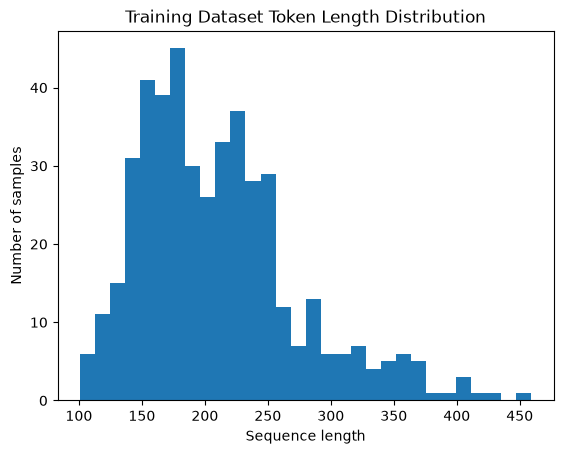

In [54]:
import matplotlib.pyplot as plt

plt.hist(lengths, bins=30)

plt.xlabel("Sequence length")
plt.ylabel("Number of samples")
plt.title("Training Dataset Token Length Distribution")

plt.show()

### 48-kod katagi izohi: Token uzunliklari taqsimotini chizish

`plt.hist(lengths, bins=30)` token uzunliklarini 30 ta oraliqqa ajratib gistogramma chizadi. Har bir ustun shu uzunlik oralig‘iga nechta namuna tushganini bildiradi.

Gorizontal o‘q tokenlar sonini, vertikal o‘q namunalar sonini ko‘rsatadi. `xlabel`, `ylabel` va `title` yozuvlarni o‘rnatadi; `plt.show()` grafikni chiqaradi. Grafik namunalar ko‘proq qaysi uzunliklarda to‘planganini ko‘rishga yordam beradi.


### 49-kod katagi izohi: Bo‘sh yakuniy katak

Bu katakda kod yozilmagan. Uni ishga tushirish hech qanday hisoblash bajarmaydi; keyingi tajriba yoki o‘qitish kodini shu yerga yozish mumkin.


In [56]:
MAX_SEQ_LENGTH=512

In [58]:
sample = formatted_train[0]

prompt_messages = [
    {
        "role": "user",
        "content": sample["question"]
    }
]

prompt = tokenizer.apply_chat_template(
    prompt_messages,
    tokenize=False,
    add_generation_prompt=True
)

full_text = sample["text"]

print("PROMPT:")
print(prompt)

print("\nFULL TEXT:")
print(full_text)

PROMPT:
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Sara builds a birdhouse that is 1 foot wide, 2 feet tall and 2 feet deep. Jake builds a birdhouse that is 16 inches wide, 20 inches tall and 18 inches deep. What is the difference in volume between the two birdhouses?<|im_end|>
<|im_start|>assistant


FULL TEXT:
<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Sara builds a birdhouse that is 1 foot wide, 2 feet tall and 2 feet deep. Jake builds a birdhouse that is 16 inches wide, 20 inches tall and 18 inches deep. What is the difference in volume between the two birdhouses?<|im_end|>
<|im_start|>assistant
To compare volumes, the measurements must be in the same units. There are 12 inches in 1 ft, so Sara’s birdhouse is 1 ft x 12 inches/ft = 12 inches wide, 2 ft x 12 inches/ft = 24 inches tall, and 2 ft x 12 inches/ft = 24 inches deep.
The volume of S

In [59]:
prompt_ids=tokenizer(
    prompt,
    add_special_tokens=False
)["input_ids"]

full_ids=tokenizer(
    full_text,
    add_special_tokens=False
)["input_ids"]

print("Prompt tokens:",len(prompt_ids))
print("Full tokens:",len(full_ids))

print(
    "Answer tokens:",
    len(full_ids)-len(prompt_ids)
)

assert full_ids[:len(prompt_ids)] == prompt_ids

Prompt tokens: 89
Full tokens: 322
Answer tokens: 233
